In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from matplotlib.ticker import StrMethodFormatter

# Locate project folder
BASE_DIR = Path.cwd()

if not (BASE_DIR / "reports").exists():
    BASE_DIR = BASE_DIR.parent

# File paths
DATA_PATH = BASE_DIR / "reports" / "clean_data.csv"
FIGURE_PATH = BASE_DIR / "reports" / "figures"

# Create figures folder
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Ensure numeric columns are numeric
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")
df["Experience_Years"] = pd.to_numeric(
    df["Experience_Years"], errors="coerce"
)
df["Performance_Rating"] = pd.to_numeric(
    df["Performance_Rating"], errors="coerce"
)

# Consistent colour scheme
COLORS = {
    "blue": "#2878B5",
    "teal": "#20A39E",
    "orange": "#F28E2B",
    "red": "#E15759",
    "purple": "#9467BD",
    "green": "#59A14F"
}

sns.set_theme(style="whitegrid", palette="deep")

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("\nFigures will be saved in:", FIGURE_PATH)

# Check required columns
required_columns = [
    "Employee_ID",
    "Department",
    "Salary",
    "Experience_Years",
    "Performance_Rating"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        "Use the expanded employee dataset."
    )


Dataset loaded successfully!
Rows: 100
Columns: ['Employee_ID', 'Employee_Name', 'Age', 'Gender', 'Department', 'City', 'Salary', 'Experience_Years', 'Performance_Rating', 'Contract_Type', 'Outlier_Flag']

Figures will be saved in: c:\training_1\day_5\ai-training-repo\reports\figures


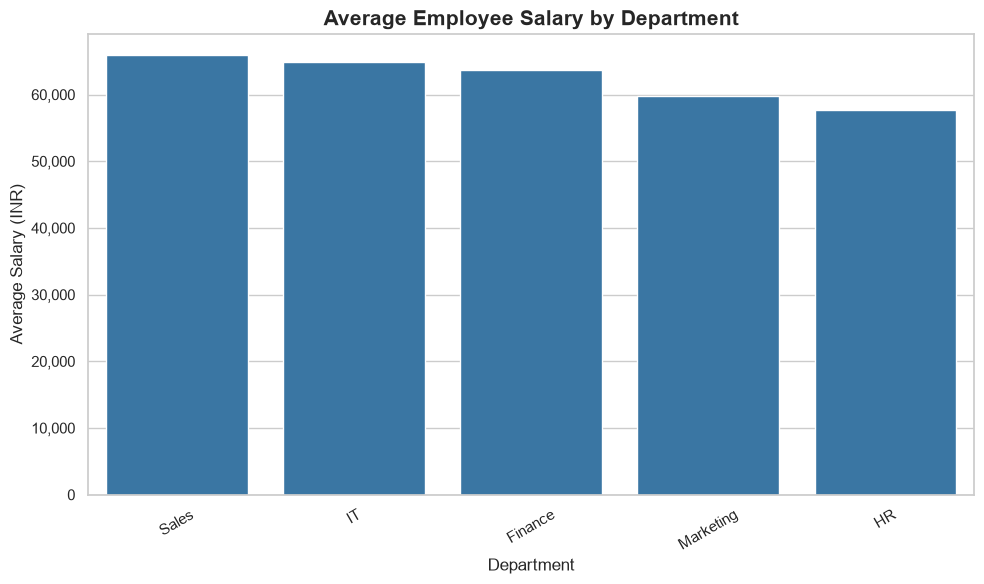

Insight: Sales has the highest average salary of ₹65,867.62.


In [2]:

# Average salary by department
department_salary = df.groupby(
    "Department"
)["Salary"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=department_salary.index,
    y=department_salary.values,
    color=COLORS["blue"]
)

plt.title("Average Employee Salary by Department",
          fontsize=15, fontweight="bold")

plt.xlabel("Department")
plt.ylabel("Average Salary (INR)")
plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Insight
highest_department = department_salary.idxmax()
highest_salary = department_salary.max()

print(
    f"Insight: {highest_department} has the highest "
    f"average salary of ₹{highest_salary:,.2f}."
)


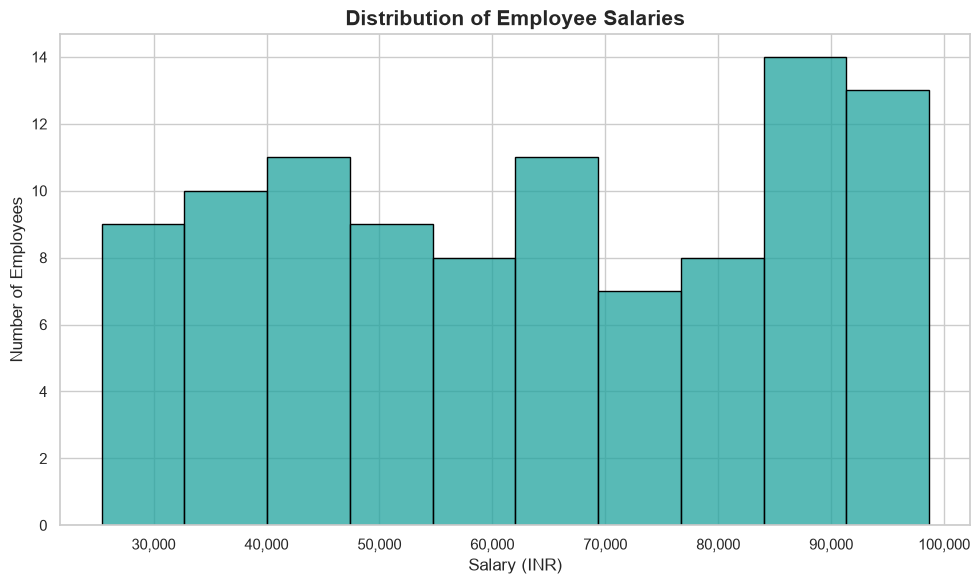

Insight: The average employee salary is ₹63,467.10. The histogram shows how employees are distributed across salary ranges.


In [3]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Salary",
    bins=10,
    color=COLORS["teal"],
    edgecolor="black"
)

plt.title("Distribution of Employee Salaries",
          fontsize=15, fontweight="bold")

plt.xlabel("Salary (INR)")
plt.ylabel("Number of Employees")

plt.gca().xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Insight
average_salary = df["Salary"].mean()

print(
    f"Insight: The average employee salary is "
    f"₹{average_salary:,.2f}. The histogram shows "
    "how employees are distributed across salary ranges."
)


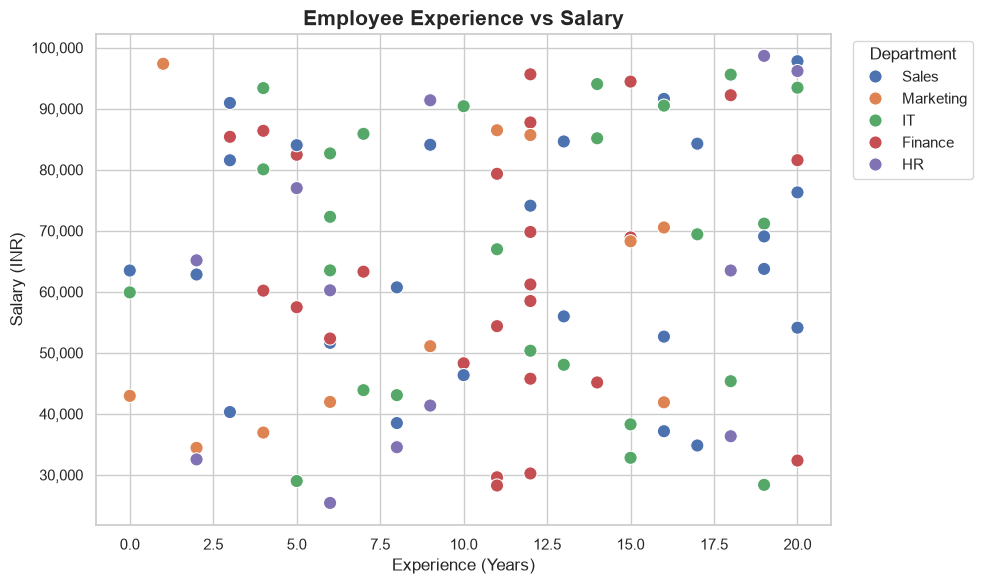

Insight: Experience and salary have a correlation of 0.119.


In [4]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Experience_Years",
    y="Salary",
    hue="Department",
    palette="deep",
    s=90
)

plt.title("Employee Experience vs Salary",
          fontsize=15, fontweight="bold")

plt.xlabel("Experience (Years)")
plt.ylabel("Salary (INR)")

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.legend(
    title="Department",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Insight
correlation = df[
    ["Experience_Years", "Salary"]
].corr().iloc[0, 1]

print(
    f"Insight: Experience and salary have a correlation "
    f"of {correlation:.3f}."
)


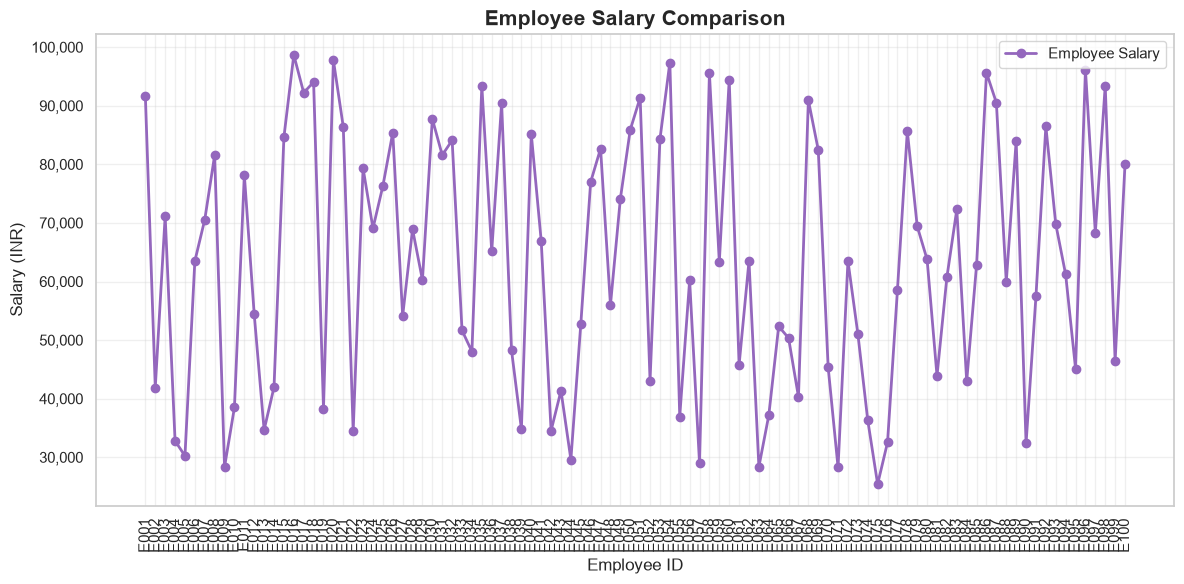

Insight: E016 has the highest salary (₹98,666), while E075 has the lowest (₹25,412).


In [5]:

# Sort employees by ID
line_data = df.sort_values("Employee_ID").copy()

plt.figure(figsize=(12, 6))

plt.plot(
    line_data["Employee_ID"],
    line_data["Salary"],
    color=COLORS["purple"],
    marker="o",
    linewidth=2,
    label="Employee Salary"
)

plt.title("Employee Salary Comparison",
          fontsize=15, fontweight="bold")

plt.xlabel("Employee ID")
plt.ylabel("Salary (INR)")

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=90)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "line_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Insight
highest = line_data.loc[line_data["Salary"].idxmax()]
lowest = line_data.loc[line_data["Salary"].idxmin()]

print(
    f"Insight: {highest['Employee_ID']} has the highest salary "
    f"(₹{highest['Salary']:,.0f}), while "
    f"{lowest['Employee_ID']} has the lowest "
    f"(₹{lowest['Salary']:,.0f})."
)


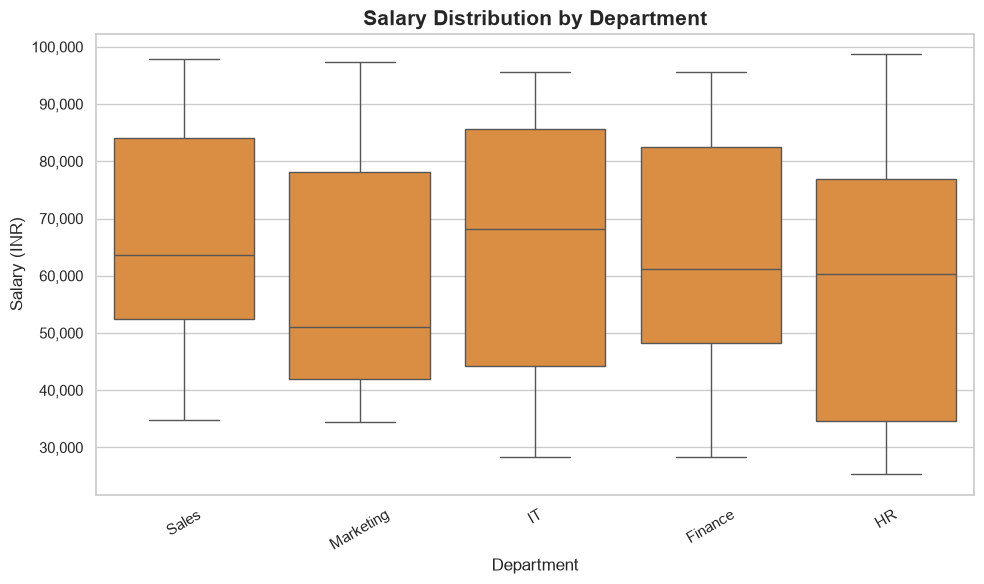

Insight: IT has the highest median salary of ₹68,200.00. The box plot also highlights potential salary outliers.


In [6]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Department",
    y="Salary",
    color=COLORS["orange"]
)

plt.title("Salary Distribution by Department",
          fontsize=15, fontweight="bold")

plt.xlabel("Department")
plt.ylabel("Salary (INR)")

plt.gca().yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "box_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Insight
department_median = df.groupby(
    "Department"
)["Salary"].median()

highest_median_department = department_median.idxmax()

print(
    f"Insight: {highest_median_department} has the highest "
    f"median salary of ₹"
    f"{department_median.max():,.2f}. "
    "The box plot also highlights potential salary outliers."
)


In [7]:

# Check all generated charts

expected_figures = [
    "bar_chart.png",
    "histogram.png",
    "scatter_plot.png",
    "line_chart.png",
    "box_plot.png"
]

print("========== VISUALISATION REPORT ==========")

for figure in expected_figures:
    file_path = FIGURE_PATH / figure

    if file_path.exists():
        print(f"SUCCESS: {figure}")
    else:
        print(f"MISSING: {figure}")

print("\nTotal charts expected:", len(expected_figures))

generated = sum(
    (FIGURE_PATH / figure).exists()
    for figure in expected_figures
)

print("Total charts generated:", generated)

print("\nAll visualisations completed!")


========== VISUALISATION REPORT ==========
SUCCESS: bar_chart.png
SUCCESS: histogram.png
SUCCESS: scatter_plot.png
SUCCESS: line_chart.png
SUCCESS: box_plot.png

Total charts expected: 5
Total charts generated: 5

All visualisations completed!


In [8]:

# ============================================
# TASK 4: PROJECT REPORT
# ============================================

from pathlib import Path
import pandas as pd

# Project paths
BASE_DIR = Path.cwd()

if not (BASE_DIR / "reports").exists():
    BASE_DIR = BASE_DIR.parent

REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

# Load cleaned data
df = pd.read_csv(REPORT_DIR / "clean_data.csv")

# Ensure numeric columns
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")
df["Experience_Years"] = pd.to_numeric(
    df["Experience_Years"], errors="coerce"
)
df["Performance_Rating"] = pd.to_numeric(
    df["Performance_Rating"], errors="coerce"
)

# Summary calculations
total_employees = len(df)
average_salary = df["Salary"].mean()
median_salary = df["Salary"].median()
average_experience = df["Experience_Years"].mean()

# Department analysis
department_salary = df.groupby(
    "Department"
)["Salary"].mean().dropna()

highest_department = department_salary.idxmax()
highest_department_salary = department_salary.max()

# City analysis
city_counts = df["City"].value_counts().dropna()

largest_city = city_counts.idxmax()
largest_city_count = city_counts.max()

# Performance analysis
performance = df.groupby(
    "Department"
)["Performance_Rating"].mean().dropna()

best_department = performance.idxmax()
best_rating = performance.max()

# Correlation
salary_experience_corr = df[
    ["Salary", "Experience_Years"]
].corr().iloc[0, 1]

# Create report
report = f"""
# EMPLOYEE CUSTOMER DATA ANALYSIS
## Project Findings Report

### 1. Problem Statement

The objective of this project is to analyse employee
data, identify patterns in salaries, departments,
experience and performance, and provide useful
recommendations for better workforce management.

### 2. Dataset Description

The analysis uses a synthetic employee dataset
containing {total_employees} cleaned employee records.

The dataset includes employee age, gender, department,
city, salary, experience, performance rating and
contract type.

Python, Pandas, NumPy, Matplotlib and Seaborn
were used for analysis and visualisation.

### 3. Three Key Insights

1. Salary:
   The overall average employee salary is
   INR {average_salary:,.2f}, while the median
   salary is INR {median_salary:,.2f}.

2. Department:
   {highest_department} has the highest average
   salary of INR {highest_department_salary:,.2f}.

3. Workforce:
   {largest_city} has the highest employee count
   with {largest_city_count} employees.
   Average employee experience is
   {average_experience:.2f} years.

Additional finding:
   The correlation between experience and salary
   is {salary_experience_corr:.3f}.
   The department with the highest average
   performance rating is {best_department}
   ({best_rating:.2f} out of 5).

### 4. Recommendations

1. Review department-wise salary structures and
   ensure compensation is aligned with employee
   responsibilities and experience.

2. Use department and performance analysis to
   identify opportunities for employee training,
   workforce planning and performance improvement.

### 5. Limitations

- The dataset is synthetic and created for practice.
- The dataset contains only {total_employees} records.
- Results may not represent an actual organisation.
- Correlation does not establish causation.
- The analysis is based on the available columns
  and may omit other important employee factors.

### 6. Conclusion

The analysis demonstrates how data cleaning,
exploratory analysis, statistical methods and
visualisations can support employee-related
business decisions.
"""

# Save report
report_path = REPORT_DIR / "project_report.md"

report_path.write_text(report, encoding="utf-8")

print("Project report generated successfully!")
print(report)



Project report generated successfully!

# EMPLOYEE CUSTOMER DATA ANALYSIS
## Project Findings Report

### 1. Problem Statement

The objective of this project is to analyse employee
data, identify patterns in salaries, departments,
experience and performance, and provide useful
recommendations for better workforce management.

### 2. Dataset Description

The analysis uses a synthetic employee dataset
containing 100 cleaned employee records.

The dataset includes employee age, gender, department,
city, salary, experience, performance rating and
contract type.

Python, Pandas, NumPy, Matplotlib and Seaborn
were used for analysis and visualisation.

### 3. Three Key Insights

1. Salary:
   The overall average employee salary is
   INR 63,467.10, while the median
   salary is INR 63,494.00.

2. Department:
   Sales has the highest average
   salary of INR 65,867.62.

3. Workforce:
   Mumbai has the highest employee count
   with 23 employees.
   Average employee experience is
   10.84 years